c:\Users\Paimon\miniconda3\envs\ml_project\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\Paimon\.cache\kagglehub\datasets\sakshigoyal7\credit-card-customers\versions\1
Unknown in CLIENTNUM: 0 
Unknown in Attrition_Flag: 0 
Unknown in Customer_Age: 0 
Unknown in Gender: 0 
Unknown in Dependent_count: 0 
Unknown in Education_Level: 1519 
Unknown in Marital_Status: 749 
Unknown in Income_Category: 1112 
Unknown in Card_Category: 0 
Unknown in Months_on_book: 0 
Unknown in Total_Relationship_Count: 0 
Unknown in Months_Inactive_12_mon: 0 
Unknown in Contacts_Count_12_mon: 0 
Unknown in Credit_Limit: 0 
Unknown in Total_Revolving_Bal: 0 
Unknown in Avg_Open_To_Buy: 0 
Unknown in Total_Amt_Chng_Q4_Q1: 0 
Unknown in Total_Trans_Amt: 0 
Unknown in Total_Trans_Ct: 0 
Unknown in Total_Ct_Chng_Q4_Q1: 0 
Unknown in Avg_Utilization_Ratio: 0 
Unknown in Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1: 0 
Unknown in Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contact

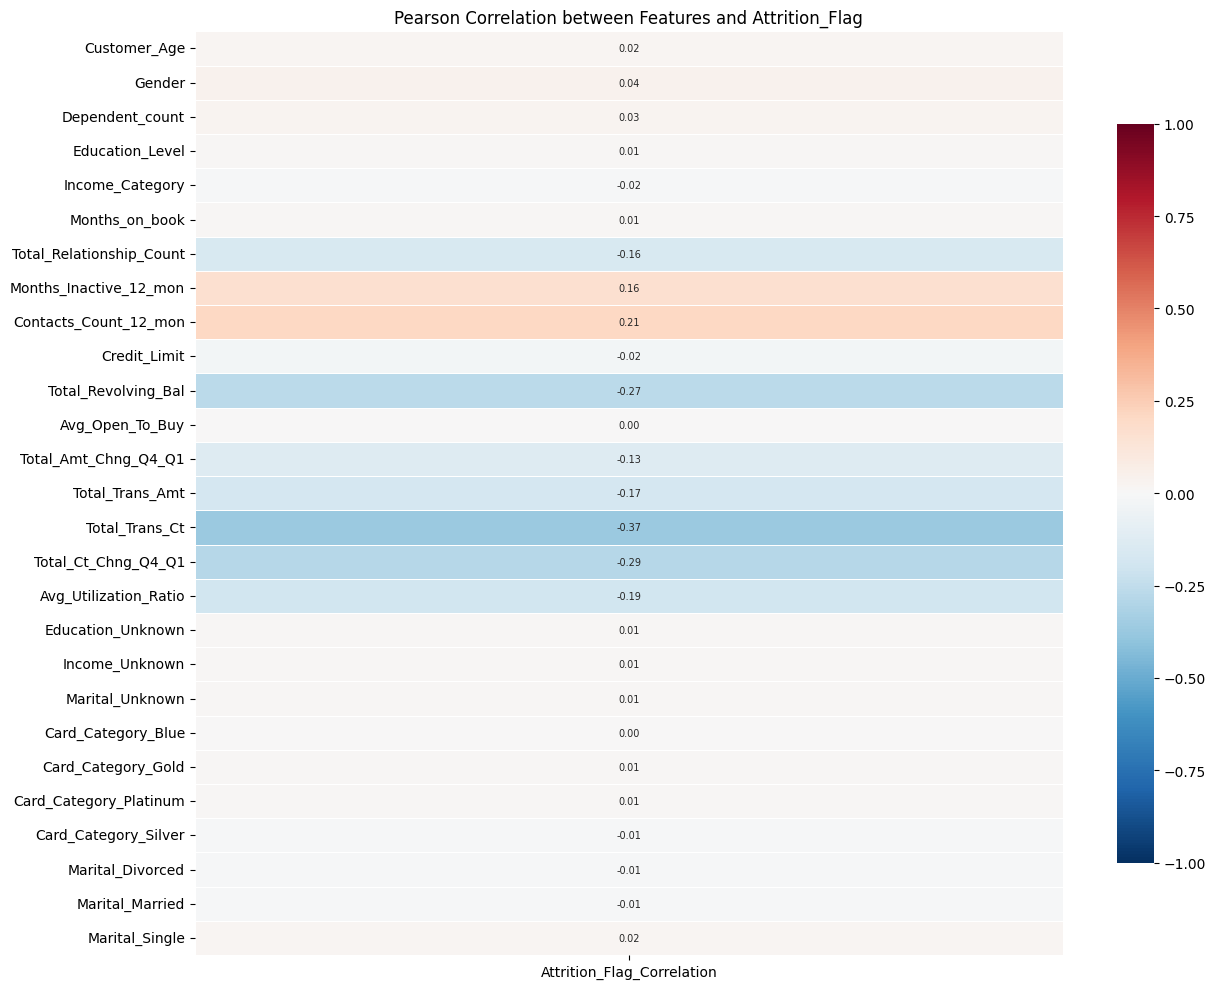

                     feature        score         pvalue  mutual_info  \
0             Total_Trans_Ct  1304.840615  4.672547e-265     0.117308   
1        Total_Ct_Chng_Q4_Q1   724.081801  7.826216e-153     0.097107   
2        Total_Revolving_Bal   624.638229  7.200815e-133     0.086718   
3      Contacts_Count_12_mon   357.053749   5.766715e-78     0.031237   
4      Avg_Utilization_Ratio   298.439252   1.074262e-65     0.056820   
5            Total_Trans_Amt   251.300721   9.267982e-56     0.158251   
6     Months_Inactive_12_mon   207.190324   2.099911e-46     0.020610   
7   Total_Relationship_Count   204.922922   6.377533e-46     0.012831   
8       Total_Amt_Chng_Q4_Q1   137.395987   1.772444e-31     0.031095   
9            Dependent_count     7.760686   5.351984e-03     0.002122   
10              Credit_Limit     4.658394   3.093137e-02     0.000305   
11              Customer_Age     2.412416   1.204155e-01     0.000000   
12            Months_on_book     0.534546   4.64723

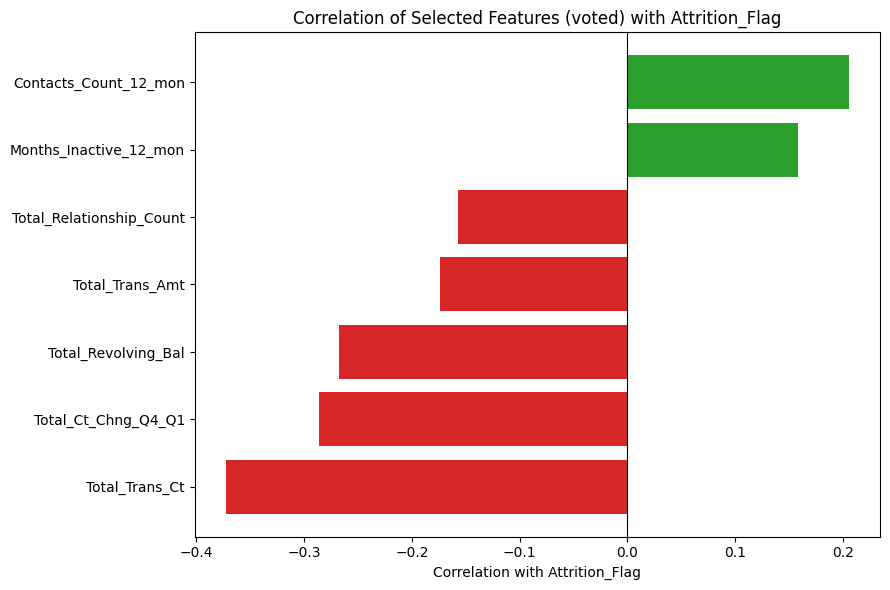

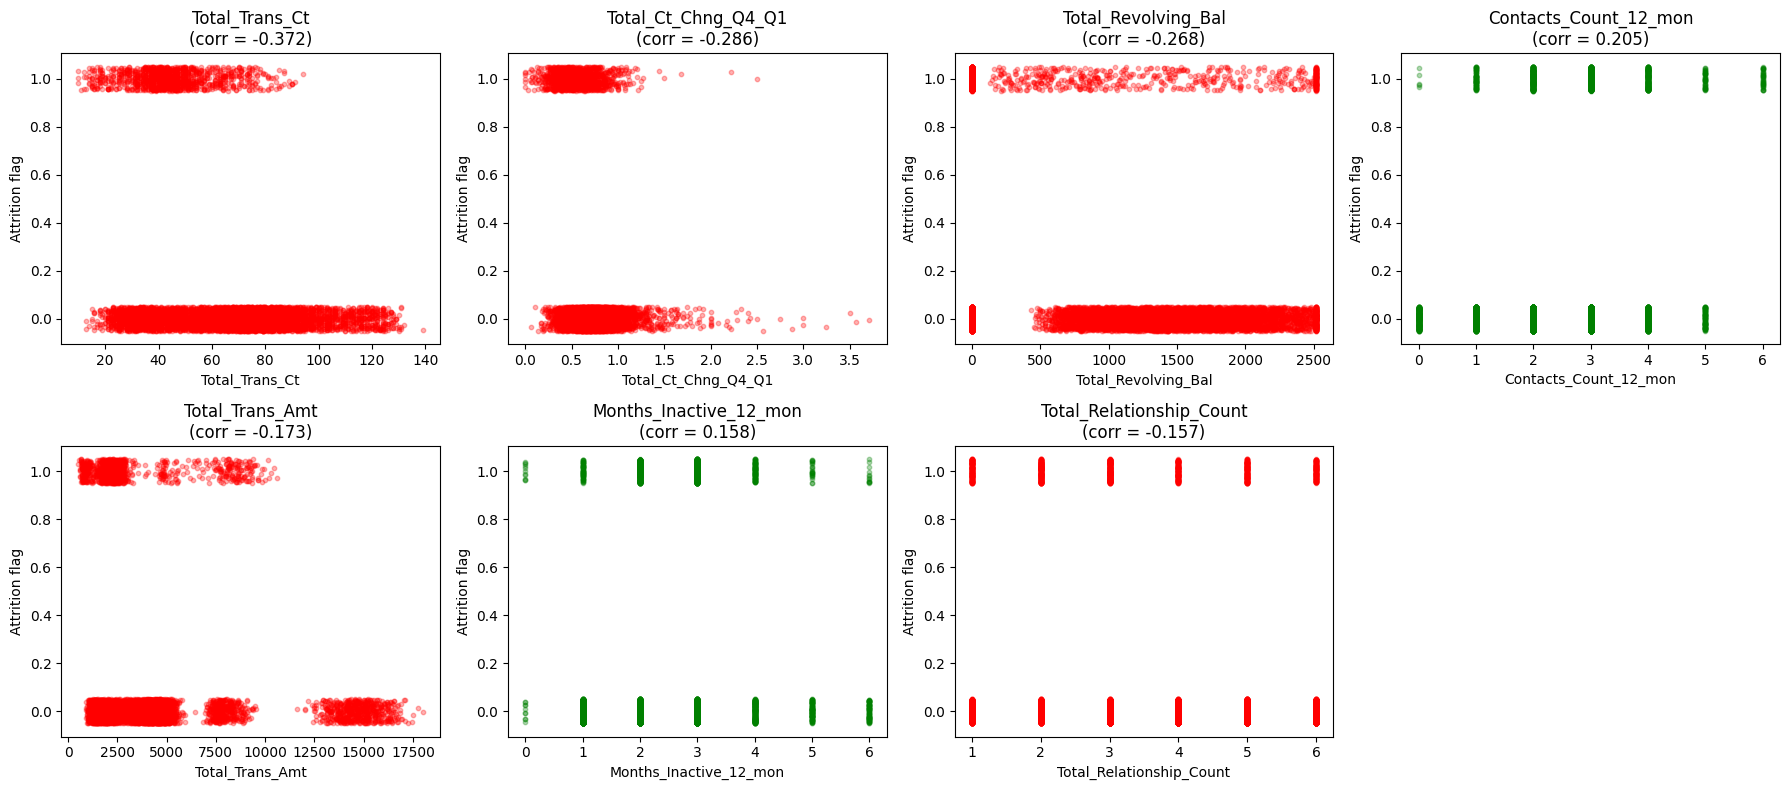

ฟีเจอร์: 25
Train: 8101 | Test: 2026

Income_Category             0.563
Card_Category_Blue          0.516
Card_Category_Silver        0.441
Gender                      0.421
Card_Category_Gold          0.234
Total_Trans_Amt             0.172
Card_Category_Platinum      0.106
Total_Trans_Ct              0.076
Total_Relationship_Count    0.071
Dependent_count             0.068
                 feature       score        pvalue  mutual_info
         Income_Category 3818.741260  0.000000e+00     0.211580
      Card_Category_Blue 2860.832605  0.000000e+00     0.116305
    Card_Category_Silver 1863.773769  0.000000e+00     0.084387
                  Gender 1793.463987  0.000000e+00     0.130455
      Card_Category_Gold  519.128770 1.972602e-111     0.030937
         Total_Trans_Amt  242.378319  7.156694e-54     0.106803
  Card_Category_Platinum   75.218274  5.036403e-18     0.006265
          Total_Trans_Ct   46.951240  7.810232e-12     0.039888
Total_Relationship_Count   42.747424  6.605692

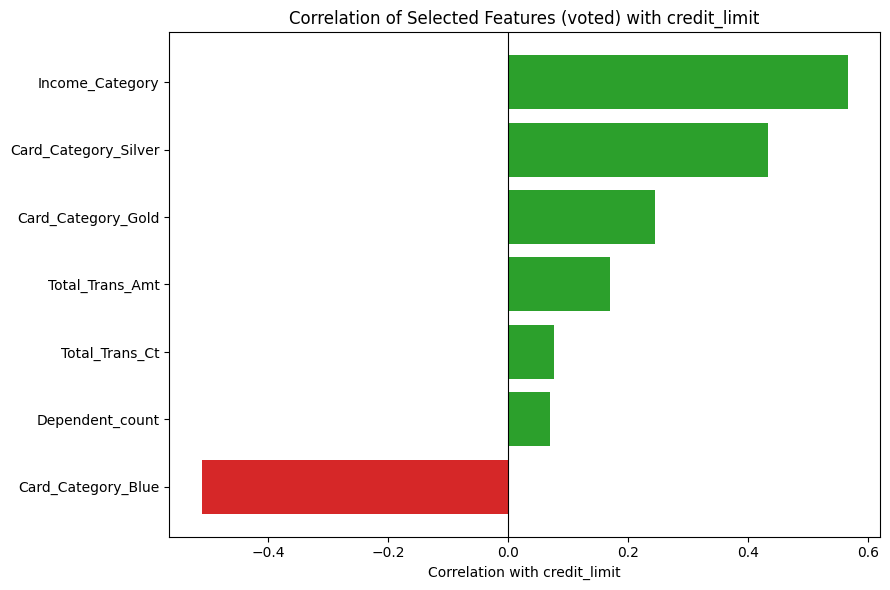

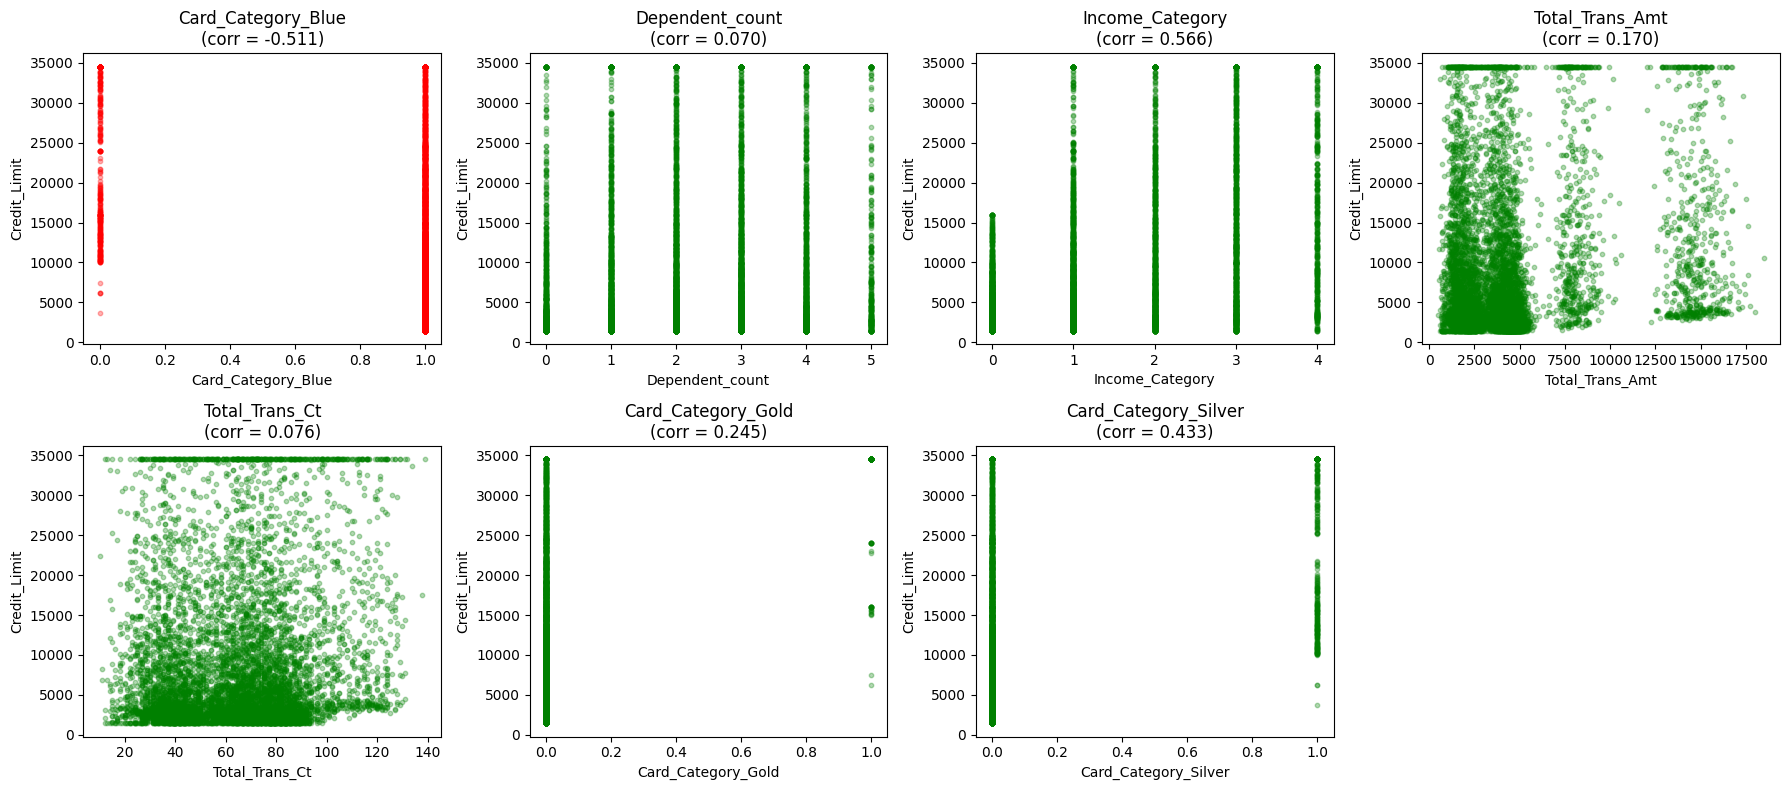

R² each fold: [0.5178384  0.55896333 0.51699789 0.55879163 0.56659464]
Mean R²: 0.5438 (+/- 0.0218)


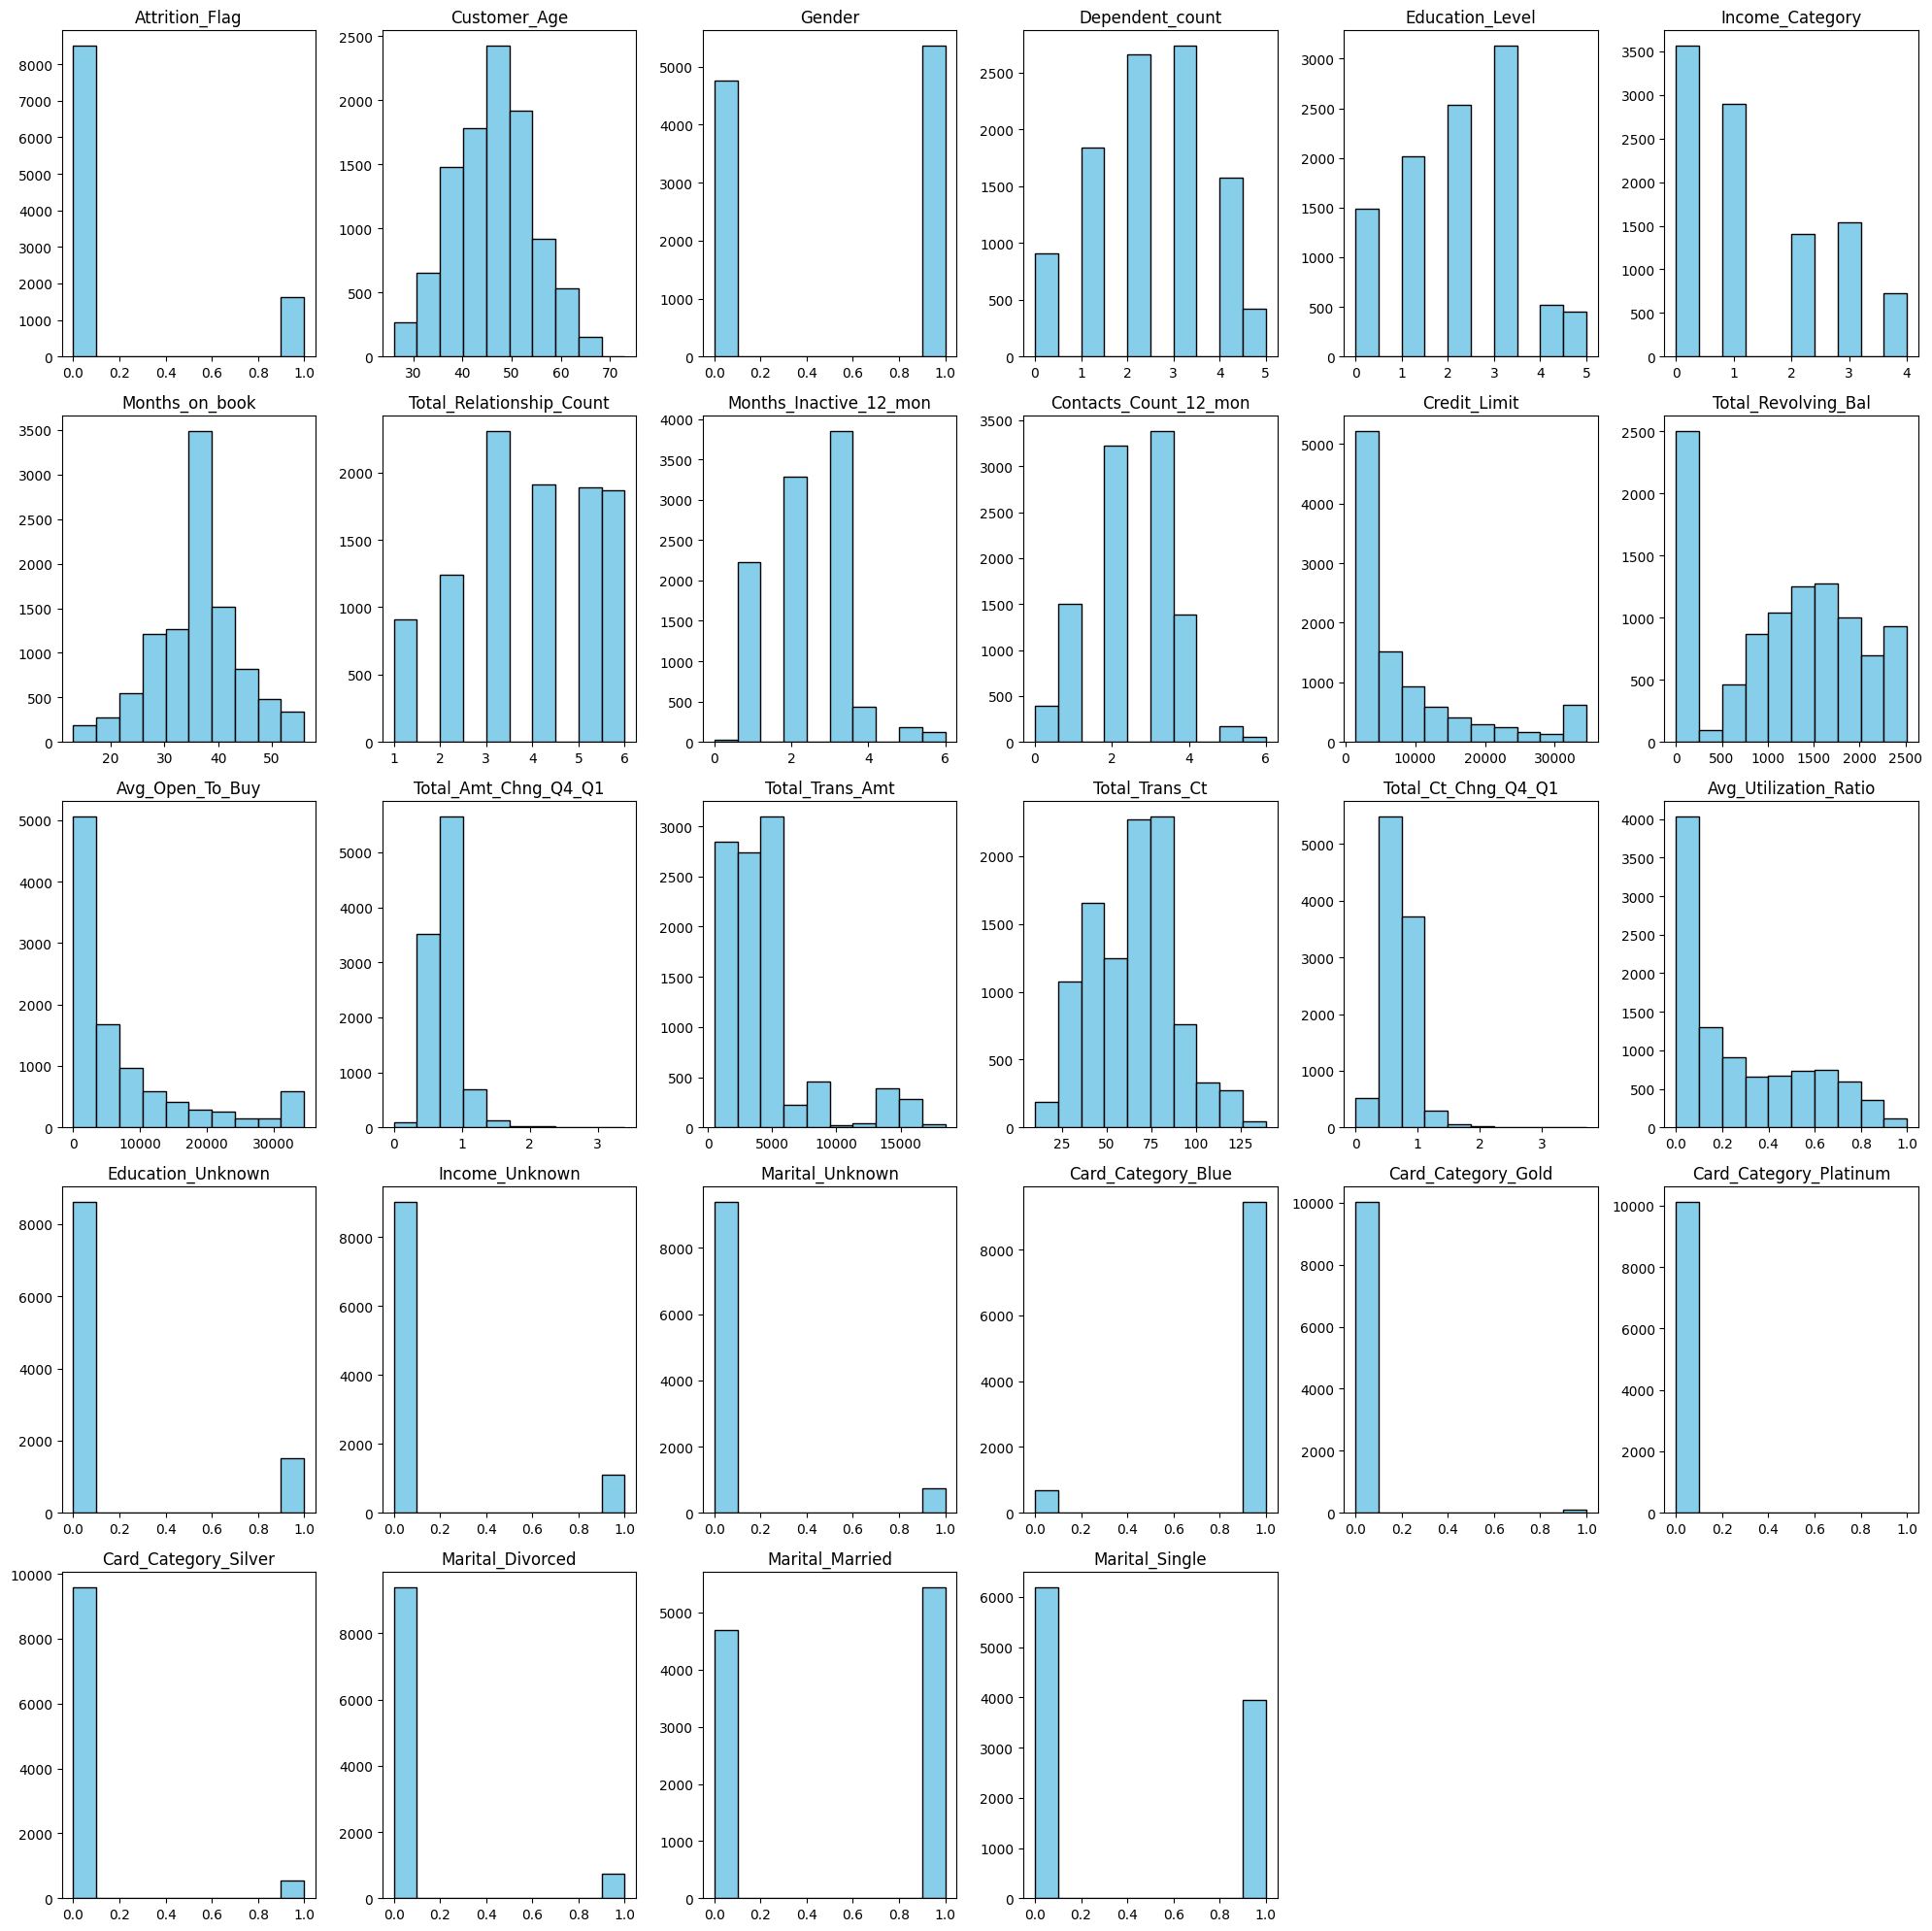

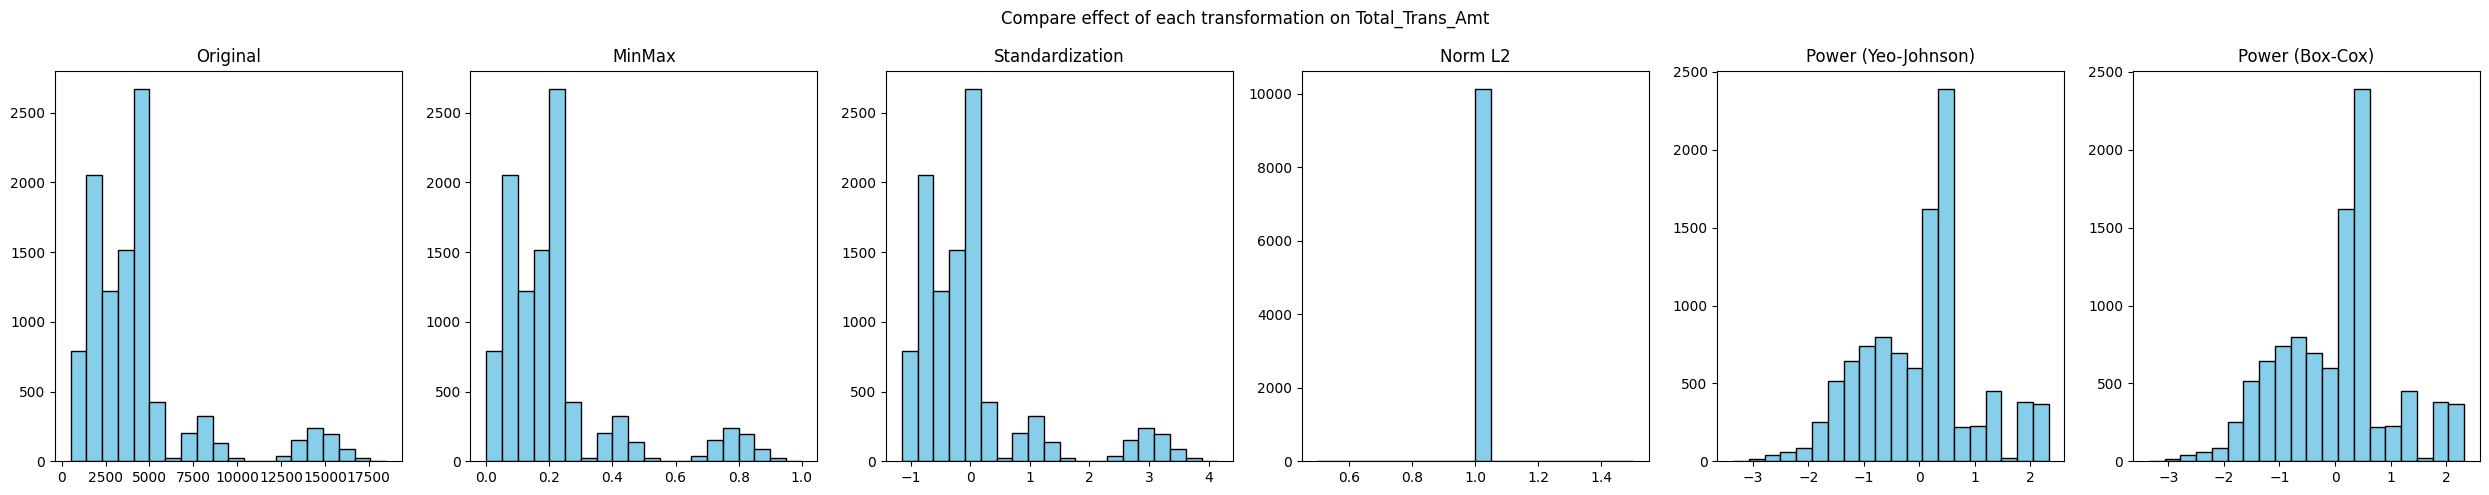

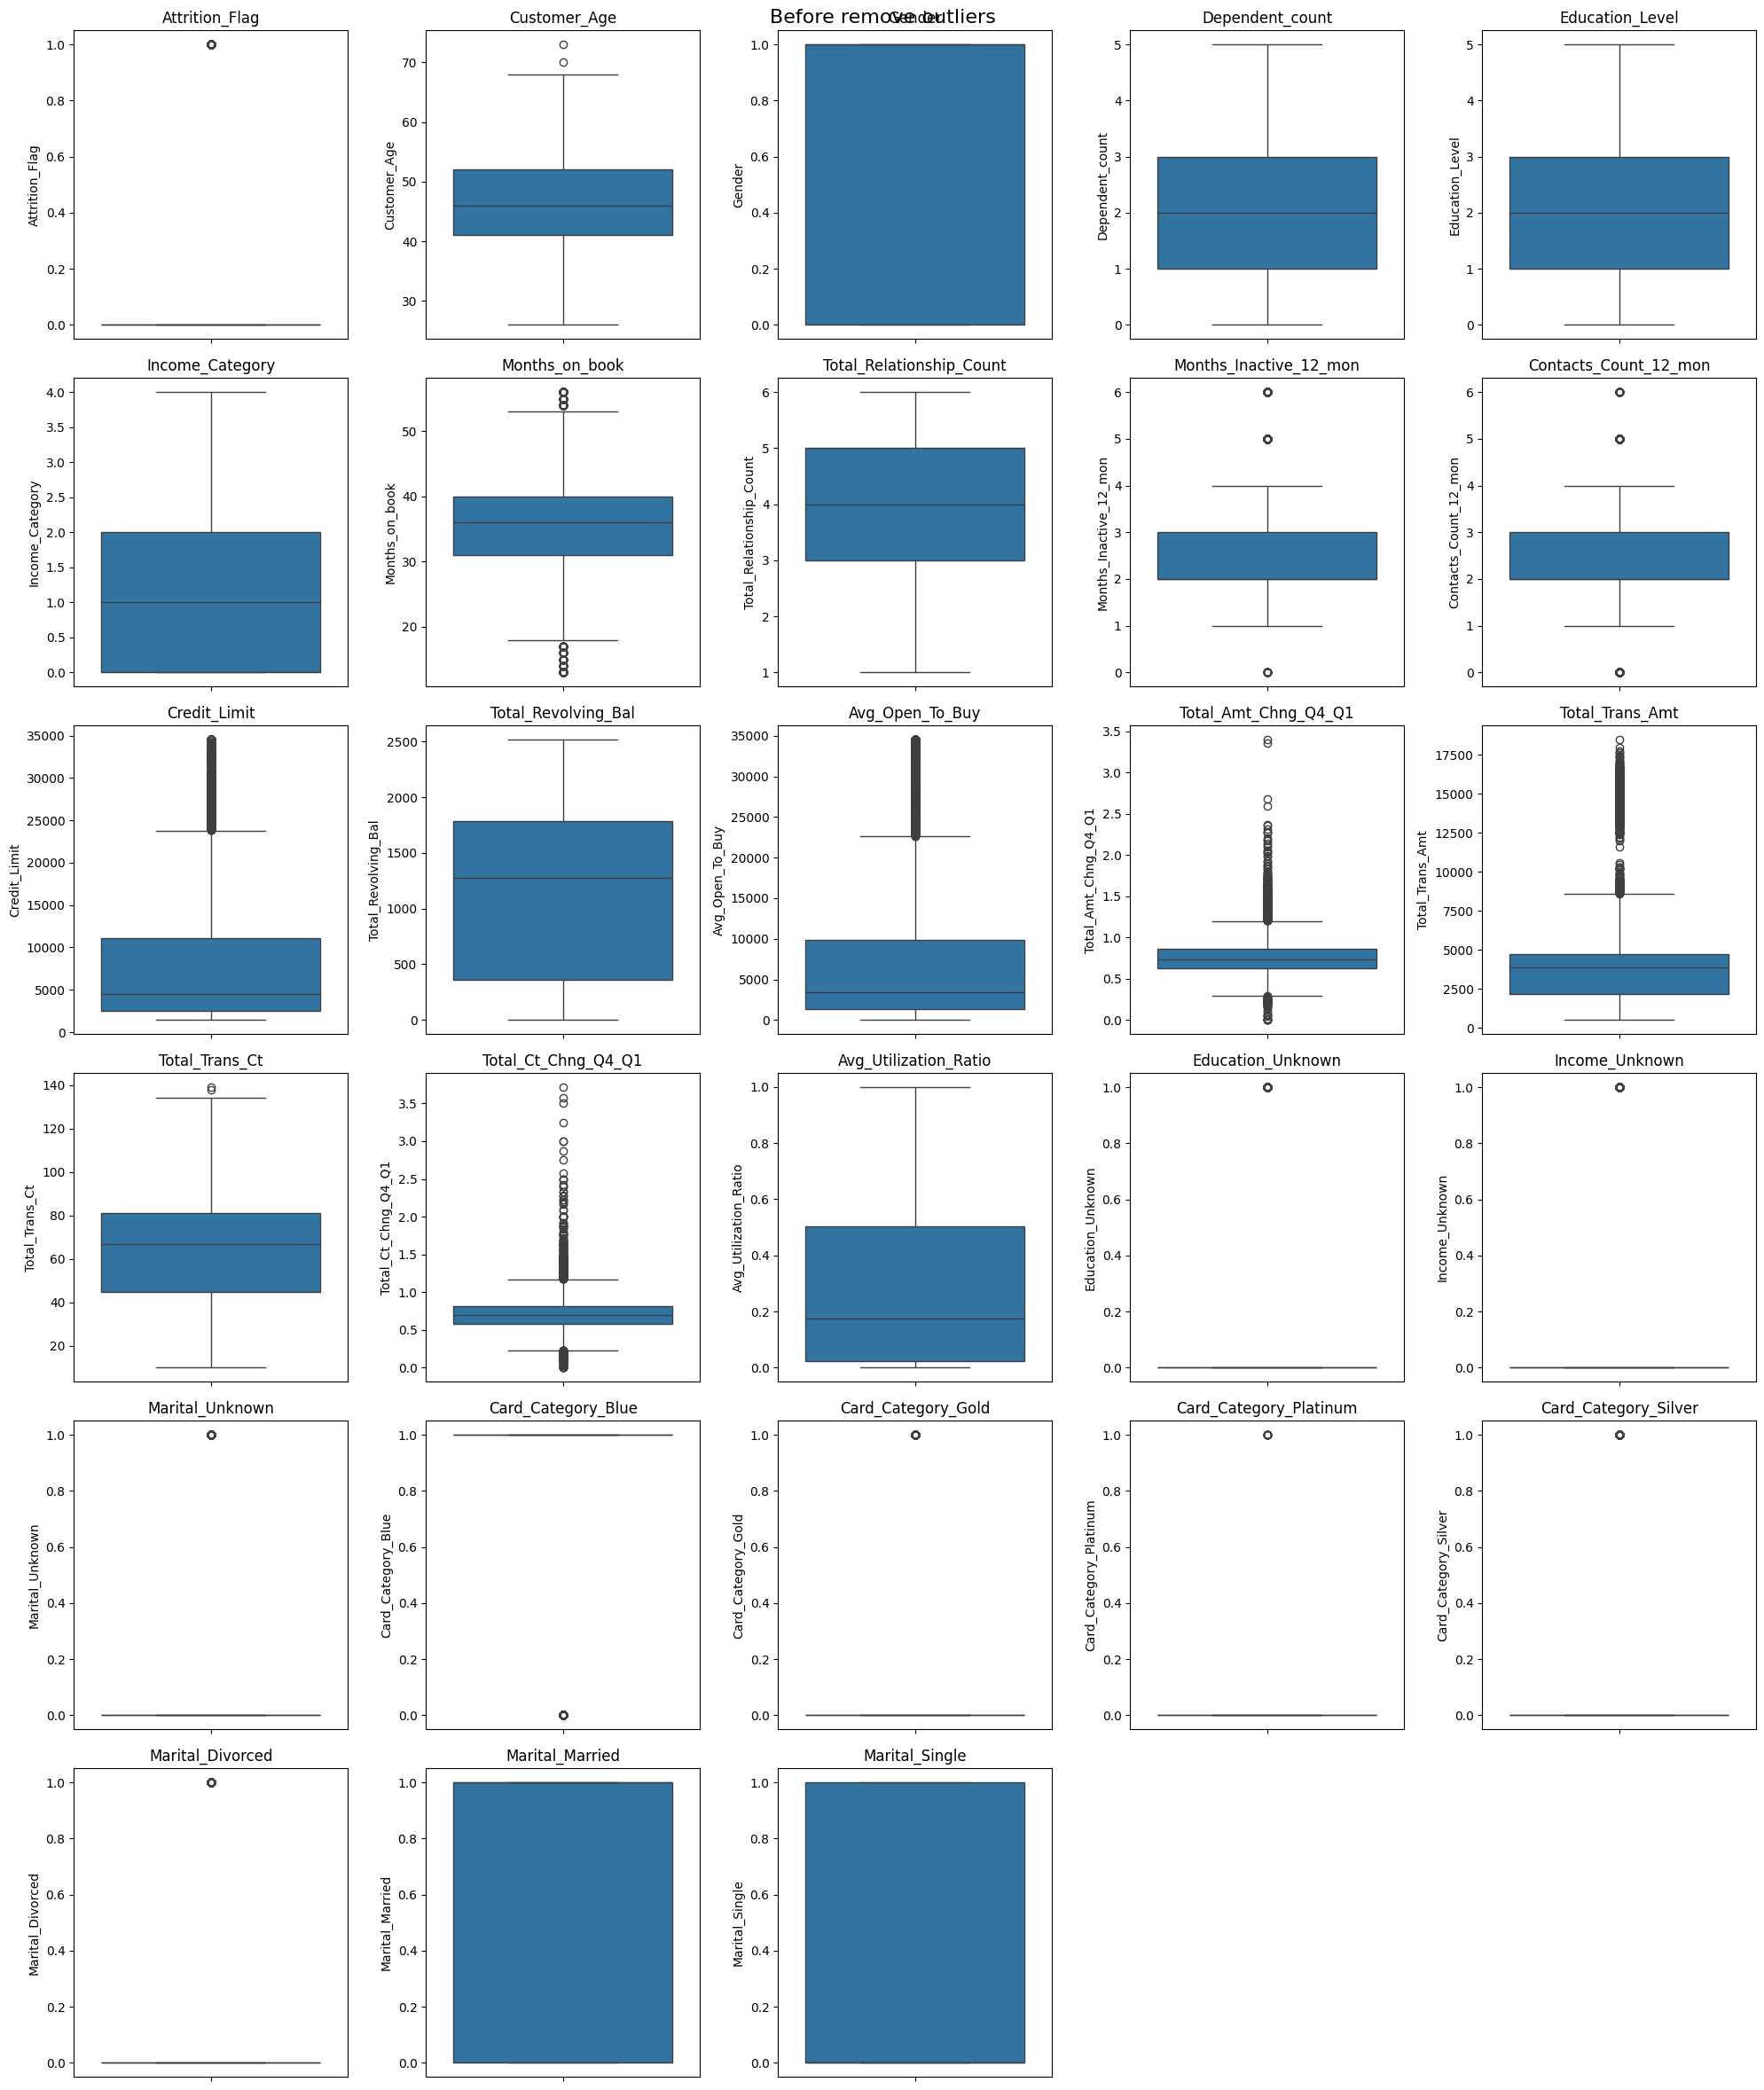

In [2]:
import import_ipynb
import data_analysis

In [3]:
data_analysis.data

,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Income_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,...,Education_Unknown,Income_Unknown,Marital_Unknown,Card_Category_Blue,Card_Category_Gold,Card_Category_Platinum,Card_Category_Silver,Marital_Divorced,Marital_Married,Marital_Single
0,0,45,0,3,1.0,2.0,39,5,1,3,...,0,0,0,True,False,False,False,False,True,False
1,0,49,1,5,3.0,0.0,44,6,1,2,...,0,0,0,True,False,False,False,False,False,True
2,0,51,0,3,3.0,3.0,36,4,1,0,...,0,0,0,True,False,False,False,False,True,False
3,0,40,1,4,1.0,0.0,34,3,4,1,...,0,0,1,True,False,False,False,False,True,False
4,0,40,0,3,0.0,2.0,21,5,1,0,...,0,0,0,True,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10122,0,50,0,2,3.0,1.0,40,3,2,3,...,0,0,0,True,False,False,False,False,False,True
10123,1,41,0,2,2.0,1.0,25,4,2,3,...,1,0,0,True,False,False,False,True,False,False
10124,1,44,1,1,1.0,0.0,36,5,3,4,...,0,0,0,True,False,False,False,False,True,False
10125,1,30,0,2,3.0,1.0,36,4,3,3,...,0,0,1,True,False,False,False,False,True,False


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

# Plain NumPy arrays, 1D labels (avoids Series/2D shape problems everywhere below)
X_train = np.asarray(data_analysis.X_scaled, dtype=float)
X_test  = np.asarray(data_analysis.X_test_scaled, dtype=float)
y_train = np.asarray(data_analysis.y_train).ravel().astype(int)
y_test  = np.asarray(data_analysis.y_test).ravel().astype(int)

print(X_train.shape, X_test.shape, "positive rate (train/test):", y_train.mean().round(3), y_test.mean().round(3))

(8101, 27) (2026, 27) positive rate (train/test): 0.161 0.16


In [ ]:
rows = []   # one dict per model, filled by the cells below

def evaluate(name, y_true, y_pred, y_score=None):
    row = {
        "model": name,
        "accuracy":  accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall":    recall_score(y_true, y_pred, zero_division=0),
        "f1":        f1_score(y_true, y_pred, zero_division=0),
        "roc_auc":   roc_auc_score(y_true, y_score) if y_score is not None else np.nan,
    }
    rows[:] = [r for r in rows if r["model"] != name]
    rows.append(row)
    return row

# Baseline: always predict the majority class
majority = np.bincount(y_train).argmax()
evaluate("baseline (majority class)", y_test, np.full_like(y_test, majority), np.full(len(y_test), 0.5))
rows[-1]

{'model': 'baseline (majority class)',
 'accuracy': 0.8395853899308984,
 'precision': 0.0,
 'recall': 0.0,
 'f1': 0.0,
 'roc_auc': 0.5}

[BCE] Iteration 0, Cost: 0.69315
[BCE] Iteration 500, Cost: 0.24769
[BCE] Iteration 1000, Cost: 0.23717
[BCE] Iteration 1500, Cost: 0.23346
[MSE] Iteration 0, Cost: 0.25000
[MSE] Iteration 500, Cost: 0.07989
[MSE] Iteration 1000, Cost: 0.07449
[MSE] Iteration 1500, Cost: 0.07231
[MSE] Iteration 2000, Cost: 0.07108
[MSE] Iteration 2500, Cost: 0.07029
[MSE] Iteration 3000, Cost: 0.06974
[MSE] Iteration 3500, Cost: 0.06934
[MSE] Iteration 4000, Cost: 0.06905
[MSE] Iteration 4500, Cost: 0.06883


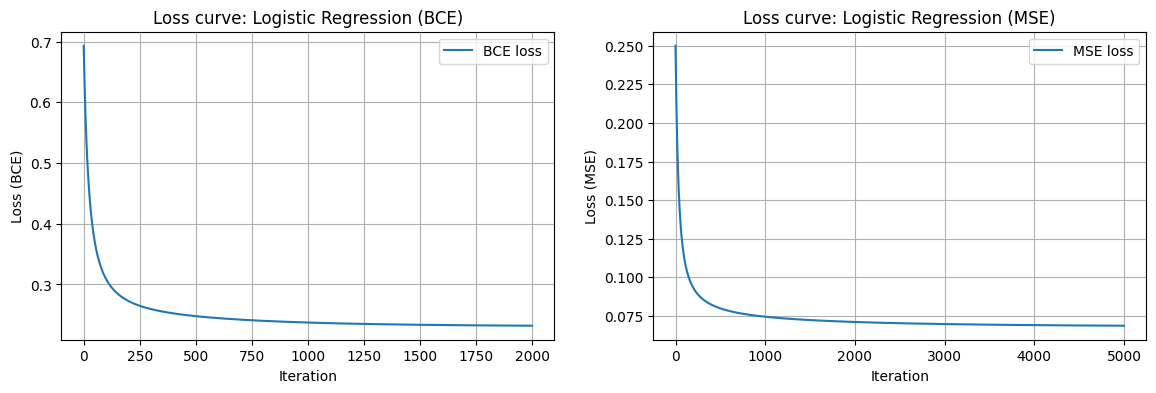

In [6]:
#Logistic regression select in rtype = MSE or BCE
class LogisticRegressionScratch:
    def __init__(self, learning_rate=0.1, num_iterations=2000, rtype='BCE', verbose=True):
        self.learning_rate = learning_rate
        self.num_iterations = num_iterations
        self.rtype = rtype
        self.verbose = verbose
        self.w = None
        self.b = None
        self.losses = []

    @staticmethod
    def sigmoid(z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def _forward(self, X):                      # shape (n, 1)
        return self.sigmoid(X @ self.w + self.b)

    def predict_proba(self, X):                 # shape (n,)
        return self._forward(np.asarray(X, dtype=float)).ravel()

    def predict(self, X, threshold=0.5):        # shape (n,)
        return (self.predict_proba(X) >= threshold).astype(int)

    def cost_function(self, h, y):
        m = len(y)
        if self.rtype == "MSE":
            return np.sum((h - y) ** 2) / m
        elif self.rtype == "BCE":
            return -np.sum(y * np.log(h + 1e-8) + (1 - y) * np.log(1 - h + 1e-8)) / m
        raise ValueError("Invalid rtype. Use 'MSE' or 'BCE'.")

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1, 1)
        m, n_features = X.shape
        self.w = np.zeros((n_features, 1))
        self.b = 0.0
        self.losses = []

        for i in range(self.num_iterations):
            probs = self._forward(X)
            self.losses.append(self.cost_function(probs, y))

            if self.rtype == "MSE":
                dz = -2 * (y - probs) * probs * (1 - probs)
            else:  # BCE
                dz = probs - y

            self.w -= self.learning_rate * (X.T @ dz) / m
            self.b -= self.learning_rate * np.sum(dz) / m

            if self.verbose and i % 500 == 0:
                print(f"[{self.rtype}] Iteration {i}, Cost: {self.losses[-1]:.5f}")
        return self

    def plot_loss(self, ax=None):
        if ax is None:
            _, ax = plt.subplots(figsize=(8, 5))
        ax.plot(self.losses, label=f'{self.rtype} loss')
        ax.set_xlabel("Iteration"); ax.set_ylabel(f"Loss ({self.rtype})")
        ax.set_title(f"Loss curve: Logistic Regression ({self.rtype})")
        ax.grid(True); ax.legend()
logreg_bce = LogisticRegressionScratch(learning_rate=0.1, num_iterations=2000, rtype='BCE').fit(X_train, y_train)
evaluate("LogReg scratch (BCE)", y_test, logreg_bce.predict(X_test), logreg_bce.predict_proba(X_test))

# MSE converges much more slowly, so give it the same learning rate and more iterations
logreg_mse = LogisticRegressionScratch(learning_rate=0.1, num_iterations=5000, rtype='MSE').fit(X_train, y_train)
evaluate("LogReg scratch (MSE)", y_test, logreg_mse.predict(X_test), logreg_mse.predict_proba(X_test))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
logreg_bce.plot_loss(axes[0]); logreg_mse.plot_loss(axes[1]); plt.show()   

In [7]:
#Decision tree
class Node:
    def __init__(self, feature=None, threshold=None, left=None, right=None, gain=None, value=None, proba=None):
        self.feature, self.threshold = feature, threshold
        self.left, self.right, self.gain = left, right, gain
        self.value, self.proba = value, proba          # set only on leaves


class DecisionTree:
    """Classifier with labels 0..K-1. Splits are exact: for each feature the data are sorted once and
    every boundary between distinct values is scored with cumulative class counts (no Python row loops)."""

    def __init__(self, min_samples=2, max_depth=5, min_gain=1e-7, max_features=None, random_state=None):
        self.max_features = max_features    # features tried per split (None = all); used by the random forest
        self.random_state = random_state
        self.min_samples = min_samples      # minimum samples needed to try a split
        self.max_depth = max_depth          # root is depth 0; nodes at max_depth become leaves
        self.min_gain = min_gain
        self.root = None

    @staticmethod
    def entropy(counts):
        """Entropy from class counts, shape (..., K)."""
        n = counts.sum(axis=-1, keepdims=True)
        p = counts / np.maximum(n, 1)
        plogp = np.where(p > 0, p * np.log2(np.where(p > 0, p, 1.0)), 0.0)
        return -plogp.sum(axis=-1)

    def best_split(self, X, y):
        n, d = X.shape
        total = np.bincount(y, minlength=self.K).astype(float)
        parent_entropy = self.entropy(total)
        best_feature, best_threshold, best_gain = None, None, 0.0
        onehot = np.eye(self.K)

        features = range(d) if not self.max_features else self.rng.choice(d, size=min(self.max_features, d), replace=False)
        for j in features:
            order = np.argsort(X[:, j], kind="stable")
            xs, ys = X[order, j], y[order]
            valid = np.nonzero(xs[:-1] < xs[1:])[0]          # split after position i, between distinct values
            if valid.size == 0:
                continue
            cum = np.cumsum(onehot[ys], axis=0)
            left = cum[valid]
            right = total - left
            n_left = valid + 1.0
            n_right = n - n_left
            gain = parent_entropy - (n_left * self.entropy(left) + n_right * self.entropy(right)) / n
            k = int(np.argmax(gain))
            if gain[k] > best_gain:
                best_feature, best_threshold, best_gain = j, xs[valid[k]], float(gain[k])   # rule: x <= threshold goes left
        return best_feature, best_threshold, best_gain

    def build_tree(self, X, y, depth=0):
        counts = np.bincount(y, minlength=self.K)
        leaf = Node(value=int(counts.argmax()), proba=counts / counts.sum())
        if len(y) < self.min_samples or depth >= self.max_depth or counts.max() == len(y):
            return leaf
        feature, threshold, gain = self.best_split(X, y)
        if feature is None or gain <= self.min_gain:
            return leaf
        mask = X[:, feature] <= threshold
        return Node(feature, threshold,
                    self.build_tree(X[mask], y[mask], depth + 1),
                    self.build_tree(X[~mask], y[~mask], depth + 1), gain)

    def fit(self, X, y, n_classes=None):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y).ravel().astype(int)     # accepts Series, 1D or (n,1) arrays
        self.K = int(n_classes) if n_classes else int(y.max()) + 1
        self.rng = np.random.default_rng(self.random_state)
        self.root = self.build_tree(X, y)
        return self

    def _route(self, X, idx, node, out):
        if node.value is not None:
            out[idx] = node.proba
            return
        go_left = X[idx, node.feature] <= node.threshold
        self._route(X, idx[go_left], node.left, out)
        self._route(X, idx[~go_left], node.right, out)

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        out = np.zeros((X.shape[0], self.K))
        self._route(X, np.arange(X.shape[0]), self.root, out)
        return out

    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)
tree = DecisionTree(min_samples=2, max_depth=5).fit(X_train, y_train)
evaluate("Decision tree scratch (depth 5)", y_test, tree.predict(X_test), tree.predict_proba(X_test)[:, 1])
rows[-1]


{'model': 'Decision tree scratch (depth 5)',
 'accuracy': 0.9304047384007897,
 'precision': 0.7690058479532164,
 'recall': 0.8092307692307692,
 'f1': 0.7886056971514243,
 'roc_auc': 0.9596581196581196}

In [8]:
#Ensemble learning: Random Forest
class RandomForestClassifierFromScratch:
    """Bagged trees; each tree sees a bootstrap sample and every split considers a random subset of max_features features
    (drawn without replacement). Class probabilities are averaged across trees."""

    def __init__(self, max_feature=None, n_trees=100, min_sample_split=2, max_depth=10, random_state=42):
        self.n_estimators = n_trees
        self.max_features = max_feature
        self.min_sample_split = min_sample_split
        self.max_depth = max_depth
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y).ravel().astype(int)
        rng = np.random.default_rng(self.random_state)
        n, d = X.shape
        self.K = int(y.max()) + 1
        mf = self.max_features or int(round(np.sqrt(d)))
        self.trees = []
        for _ in range(self.n_estimators):
            rows_idx = rng.integers(0, n, size=n)                    # bootstrap sample
            tree = DecisionTree(self.min_sample_split, self.max_depth, max_features=mf,
                                random_state=int(rng.integers(0, 2**31 - 1)))
            tree.fit(X[rows_idx], y[rows_idx], n_classes=self.K)
            self.trees.append(tree)
        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        probs = np.zeros((X.shape[0], self.K))
        for tree in self.trees:
            probs += tree.predict_proba(X)
        return probs / self.n_estimators

    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)
rf = RandomForestClassifierFromScratch(n_trees=100, max_depth=10, random_state=42).fit(X_train, y_train)   # max_features = sqrt(25) = 5
evaluate("Random forest scratch", y_test, rf.predict(X_test), rf.predict_proba(X_test)[:, 1])
rows[-1]

{'model': 'Random forest scratch',
 'accuracy': 0.9491609081934848,
 'precision': 0.937007874015748,
 'recall': 0.7323076923076923,
 'f1': 0.8221070811744386,
 'roc_auc': 0.9854149143038031}

In [9]:
#Ensemble learning: Stacking classifiers, Gradient Boosting (GB), Extreme-Gradient Boosting (XGBoost)
class GBMClassifier:
    """Multiclass gradient boosting with softmax loss. Each round fits one regression tree per class to the
    negative gradient (y - p); the tree's own leaf means are used as the update, and the same update is used
    in fit() and predict(). logitboost=True uses the K-class LogitBoost working response with sample weights."""

    def __init__(self, logitboost=False, learning_rate=0.1, n_estimators=100, max_depth=3, random_state=0):
        self.logitboost = logitboost
        self.learning_rate = learning_rate
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.random_state = random_state

    @staticmethod
    def _softmax(z):
        z = z - z.max(axis=1, keepdims=True)
        e = np.exp(z)
        return e / e.sum(axis=1, keepdims=True)

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y).ravel().astype(int)
        self.K = int(y.max()) + 1
        Y = np.eye(self.K)[y]
        self.trees = {k: [] for k in range(self.K)}
        F = np.zeros((len(y), self.K))

        for _ in range(self.n_estimators):
            P = self._softmax(F)                      # same probabilities for all classes in this round
            for k in range(self.K):
                if self.logitboost:
                    w = np.clip(P[:, k] * (1 - P[:, k]), 1e-6, None)
                    r = np.clip((self.K - 1) / self.K * (Y[:, k] - P[:, k]) / w, -4, 4)
                else:
                    w, r = None, Y[:, k] - P[:, k]
                tree = DecisionTreeRegressor(criterion='friedman_mse', max_depth=self.max_depth,
                                             random_state=self.random_state)
                tree.fit(X, r, sample_weight=w)
                self.trees[k].append(tree)
                F[:, k] += self.learning_rate * tree.predict(X)
        return self

    def decision_function(self, X):
        X = np.asarray(X, dtype=float)
        F = np.zeros((X.shape[0], self.K))
        for k in range(self.K):
            for tree in self.trees[k]:
                F[:, k] += self.learning_rate * tree.predict(X)
        return F

    def predict_proba(self, X):
        return self._softmax(self.decision_function(X))

    def predict(self, X):
        return self.decision_function(X).argmax(axis=1)

gbc = GBMClassifier(learning_rate=0.1, n_estimators=100, max_depth=3, random_state=0).fit(X_train, y_train)
evaluate("Gradient boosting scratch", y_test, gbc.predict(X_test), gbc.predict_proba(X_test)[:, 1])
rows[-1]

{'model': 'Gradient boosting scratch',
 'accuracy': 0.9466929911154985,
 'precision': 0.9322709163346613,
 'recall': 0.72,
 'f1': 0.8125,
 'roc_auc': 0.9767747478858589}

In [10]:
#Naïve Bayes Classification (from “Discrete Mathematics” course; if any)
class NaiveBayes:
    """Gaussian Naive Bayes with variance smoothing (same idea as scikit-learn's var_smoothing)."""

    def __init__(self, var_smoothing=1e-9):
        self.var_smoothing = var_smoothing

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y).ravel()
        self.classes = np.unique(y)
        self.mean = np.array([X[y == c].mean(axis=0) for c in self.classes])
        self.variance = np.array([X[y == c].var(axis=0) for c in self.classes])
        self.variance += self.var_smoothing * X.var(axis=0).max()      # avoids division by zero
        self.priors = np.array([(y == c).mean() for c in self.classes])
        return self

    def log_posterior(self, X):
        X = np.asarray(X, dtype=float)
        out = []
        for i in range(len(self.classes)):
            log_pdf = -0.5 * np.log(2 * np.pi * self.variance[i]) - (X - self.mean[i]) ** 2 / (2 * self.variance[i])
            out.append(np.log(self.priors[i]) + log_pdf.sum(axis=1))
        return np.column_stack(out)

    def predict_proba(self, X):
        lp = self.log_posterior(X)
        lp -= lp.max(axis=1, keepdims=True)
        p = np.exp(lp)
        return p / p.sum(axis=1, keepdims=True)

    def predict(self, X):
        return self.classes[self.log_posterior(X).argmax(axis=1)]
nb = NaiveBayes().fit(X_train, y_train)
evaluate("Naive Bayes scratch", y_test, nb.predict(X_test), nb.predict_proba(X_test)[:, 1])
rows[-1]  

{'model': 'Naive Bayes scratch',
 'accuracy': 0.8761105626850938,
 'precision': 0.6267123287671232,
 'recall': 0.563076923076923,
 'f1': 0.593192868719611,
 'roc_auc': 0.8369158413602857}

In [13]:
#Support vector machine
class SVMScratch:
    def __init__(self, C=1000.0, learning_rate=0.1, num_iterations=3000,
                 class_weight=None, verbose=False):
        self.C = C
        self.learning_rate = learning_rate
        self.num_iterations = num_iterations
        self.class_weight = class_weight
        self.verbose = verbose
        self.w = None
        self.b = 0.0
        self.losses = []

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y).ravel().astype(int)
        y_pm = np.where(y == 1, 1.0, -1.0)
        m, n = X.shape

        sw = np.ones(m)
        if self.class_weight == "balanced":
            for c in (0, 1):
                sw[y == c] = m / (2.0 * (y == c).sum())

        self.w = np.zeros(n)
        self.b = 0.0
        self.losses = []

        for t in range(1, self.num_iterations + 1):
            margins = y_pm * (X @ self.w + self.b)
            viol = margins < 1                          # จุดที่ละเมิด margin
            coef = sw * viol * y_pm
            grad_w = self.w / self.C - (X * coef[:, None]).sum(axis=0) / m
            grad_b = -coef.sum() / m
            self.w -= self.learning_rate * grad_w
            self.b -= self.learning_rate * grad_b

            loss = 0.5 * (self.w @ self.w) / self.C + np.mean(sw * np.maximum(0, 1 - margins))
            self.losses.append(loss)
            if self.verbose and t % 500 == 0:
                print(f"[SVM] iter {t}, loss {loss:.5f}")
        return self

    def decision_function(self, X):
        return np.asarray(X, dtype=float) @ self.w + self.b

    def predict_proba(self, X):
        z = np.clip(self.decision_function(X), -500, 500)
        return 1 / (1 + np.exp(-z))

    def predict(self, X):
        return (self.decision_function(X) >= 0).astype(int)

    def plot_loss(self, ax=None, title="Loss curve: SVM (scratch)"):
        if ax is None:
            _, ax = plt.subplots(figsize=(8, 5))
        ax.plot(self.losses)
        ax.set_xlabel("Iteration"); ax.set_ylabel("Hinge loss + L2 term")
        ax.set_title(title); ax.grid(True)

svm = SVMScratch().fit(X_train, y_train)
evaluate("SVM scratch (linear)", y_test, svm.predict(X_test), svm.predict_proba(X_test))
rows[-1]

{'model': 'SVM scratch (linear)',
 'accuracy': 0.8993089832181639,
 'precision': 0.7894736842105263,
 'recall': 0.5076923076923077,
 'f1': 0.6179775280898876,
 'roc_auc': 0.9061511328177995}

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Random forest scratch,0.9492,0.9370,0.7323,0.8221,0.9854
Gradient boosting scratch,0.9467,0.9323,0.7200,0.8125,0.9768
Decision tree scratch (depth 5),0.9304,0.7690,0.8092,0.7886,0.9597
LogReg scratch (MSE),0.9013,0.7907,0.5231,0.6296,0.9050
LogReg scratch (BCE),0.8993,0.7814,0.5169,0.6222,0.9122
SVM scratch (linear),0.8993,0.7895,0.5077,0.6180,0.9062
Naive Bayes scratch,0.8761,0.6267,0.5631,0.5932,0.8369
baseline (majority class),0.8396,0.0000,0.0000,0.0000,0.5000


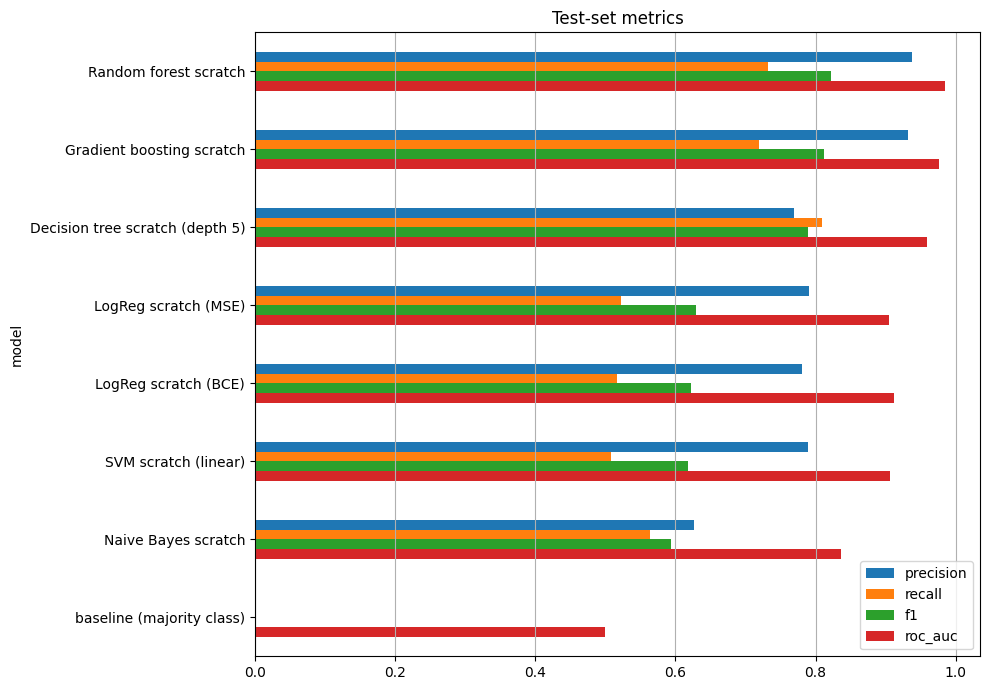

In [14]:
results = pd.DataFrame(rows).set_index("model").sort_values("f1", ascending=False)
display(results.round(4))

ax = results[["precision", "recall", "f1", "roc_auc"]].plot.barh(figsize=(10, 7))
ax.set_title("Test-set metrics"); ax.invert_yaxis(); ax.grid(axis="x"); plt.tight_layout(); plt.show()